# A/B-тест лендинга: повлияла ли новая версия на конверсию?

> **Решение по результатам исследования:** статистически значимое изменение конверсии не выявлено. На очищенной выборке конверсия новой версии немного ниже, но данных недостаточно, чтобы утверждать, что изменение вызвало этот эффект.

| Масштаб после очистки | Основная метрика | Контрольная версия | Новая версия | p-value |
|:--|:--|--:|--:|--:|
| **288 635 наблюдений** | **Конверсия** | **12,04%** | **11,87%** | **0,1604** |

**Вопрос исследования:** стоит ли заменять старый лендинг на новый ради повышения конверсии пользователей?

**Схема анализа:** `Данные -> Аудит качества -> Очистка -> Анализ стабильности групп -> Проверка гипотез -> Оценка неопределённости -> Вывод`


## 1. Постановка задачи

Две группы пользователей видят разные версии лендинга: **control ->  old_page**, **treatment -> new_page**. Целевая переменная `converted` показывает, совершил ли пользователь конверсию (`1`) или нет (`0`).

**Основная метрика** — доля сконвертировавшихся пользователей в каждой группе. Для надёжного сравнения сначала проверим корректность записей и назначения страницы, а затем сравним конверсии статистическим тестом.

### 1.1 Загрузка и первичный обзор

Исходные данные загружаются из `data_ab.csv` в Colab. Файл данных необходимо предоставить отдельно.

In [1]:
import pandas as pd
import numpy as np
from statsmodels.stats.proportion import proportions_ztest
import matplotlib.pyplot as plt
import scipy.stats as sts

In [2]:
from google.colab import files
files.upload()

Saving data_ab.csv to data_ab.csv


{'data_ab.csv': b'user_id,timestamp,group,landing_page,converted\n851104,2025-01-21 22:11:48.556739,control,old_page,0\n804228,2025-01-12 08:01:45.159739,control,old_page,0\n661590,2025-01-11 16:55:06.154213,treatment,new_page,0\n853541,2025-01-08 18:28:03.143765,treatment,new_page,0\n864975,2025-01-21 01:52:26.210827,control,old_page,1\n936923,2025-01-10 15:20:49.083499,control,old_page,0\n679687,2025-01-19 03:26:46.940749,treatment,new_page,1\n719014,2025-01-17 01:48:29.539573,control,old_page,0\n817355,2025-01-04 17:58:08.979471,treatment,new_page,1\n839785,2025-01-15 18:11:06.610965,treatment,new_page,1\n929503,2025-01-18 05:37:11.527370,treatment,new_page,0\n834487,2025-01-21 22:37:47.774891,treatment,new_page,0\n803683,2025-01-09 06:05:16.222706,treatment,new_page,0\n944475,2025-01-22 01:31:09.573836,treatment,new_page,0\n718956,2025-01-22 11:45:11.327945,treatment,new_page,0\n644214,2025-01-22 02:05:21.719434,control,old_page,1\n847721,2025-01-17 14:01:00.090575,control,old_page

In [3]:
df = pd.read_csv('data_ab.csv')
df.head()

,user_id,timestamp,group,landing_page,converted
0,851104,2025-01-21 22:11:48.556739,control,old_page,0
1,804228,2025-01-12 08:01:45.159739,control,old_page,0
2,661590,2025-01-11 16:55:06.154213,treatment,new_page,0
3,853541,2025-01-08 18:28:03.143765,treatment,new_page,0
4,864975,2025-01-21 01:52:26.210827,control,old_page,1


In [4]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 294478 entries, 0 to 294477
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   user_id       294478 non-null  int64 
 1   timestamp     294478 non-null  object
 2   group         294478 non-null  object
 3   landing_page  294478 non-null  object
 4   converted     294478 non-null  int64 
dtypes: int64(2), object(3)
memory usage: 11.2+ MB


In [5]:
df.isna().sum()

,0
user_id,0
timestamp,0
group,0
landing_page,0
converted,0


In [6]:
df['timestamp'] = pd.to_datetime(df['timestamp'])

## 2. Аудит качества данных

Перед сравнением версий важно исключить технические артефакты: повторные `user_id` и несоответствие экспериментальной группы фактически показанной странице.

### 2.1 Повторные пользователи

Проверяем количество уникальных пользователей и встречаются ли ID чаще двух раз.

In [7]:
df['user_id'].nunique(), len(df)

(290584, 294478)

In [8]:
(df['user_id'].value_counts() > 2).sum()

np.int64(0)

**Наблюдение:** обнаружены **3 894 повторяющихся `user_id`**, каждый из которых встречается ровно дважды. Проверим структуру дублей, время между наблюдениями, назначение группы и конверсию.

In [9]:

dupl_mask = df.duplicated(subset=['user_id'], keep=False) #дубликаты по айди
x = np.arange(0, 7788)
dupl_df = df[dupl_mask].copy().reset_index(drop = True) #дальше работа с номерами поэтому нужно сбросит ьиндексы
dupl_df = dupl_df.sort_values(['user_id', 'timestamp'], ascending= [False, True]) #сортировка чтобы сначала было первое вхождение юзера а потом второе
dupl_df.head(20)
dupl_f = dupl_df[x%2 == 0].reset_index(drop = True) #первые вхождения
dypl_s = dupl_df[x%2 == 1].reset_index(drop = True) #вторые вхождения

Text(0, 0.5, 'Количество')

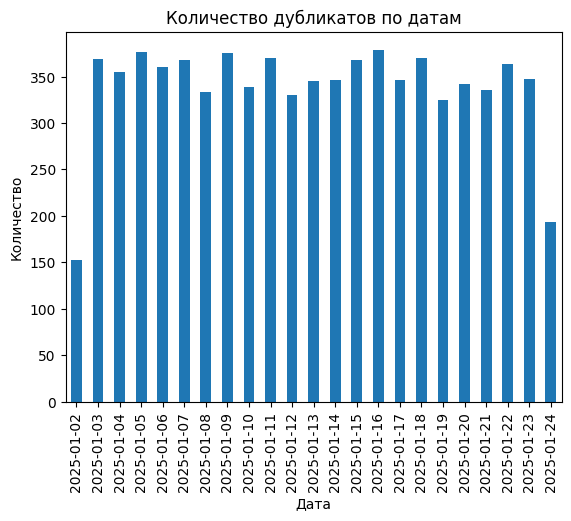

In [10]:
dupl_df['date'] = dupl_df['timestamp'].dt.date #забрали значение даты
date_counts = dupl_df['date'].value_counts().sort_index() #посчитали сколько раз встречаются даты и отсортировали для графика

date_counts.plot(kind='bar')
plt.title('Количество дубликатов по датам')
plt.xlabel('Дата')
plt.ylabel('Количество')



0


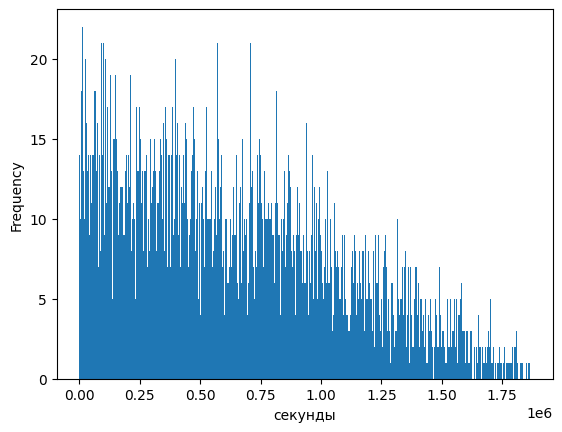

In [11]:
time_diff = (dypl_s['timestamp'] - dupl_f['timestamp']).dt.total_seconds() # посчитали время между дубликатами

time_diff.plot(kind = 'hist', xlabel = 'cекунды', bins = 500)

print((time_diff < 300).sum())

In [12]:
gr_match_musk = (dupl_f['group'] == dypl_s['group']) #у скольких дубликатов отличаются группы
lend_march_musk = (dupl_f['landing_page'] == dypl_s['landing_page']) # у скольких дубликатов отличаются страницы
print((gr_match_musk & lend_march_musk).sum()) # выведем кол-во во всех комбинациях
print((gr_match_musk & (~lend_march_musk)).sum())
print(((~gr_match_musk) & (~lend_march_musk)).sum())
print(((~gr_match_musk) & (lend_march_musk)).sum())


1
1998
0
1895


In [13]:
corr11_mask = ((dupl_f['converted'] == 1) & (dypl_s['converted']== 1)) # посчитаем как менялся покатель конвертацию у пользователей с двумя включениями
corr10_mask = ((dupl_f['converted'] == 1) & (dypl_s['converted']== 0))
corr01_mask = ((dupl_f['converted'] == 0) & (dypl_s['converted']== 1))
corr00_mask = ((dupl_f['converted'] == 0) & (dypl_s['converted']== 0))
print(corr11_mask.sum())
print(corr10_mask.sum())
print(corr01_mask.sum())
print(corr00_mask.sum())
corr = dupl_f['converted'].reset_index(drop=True).corr(dypl_s['converted'].reset_index(drop=True))
print(corr)

64
452
412
2966
0.002137756924171314


<Axes: >

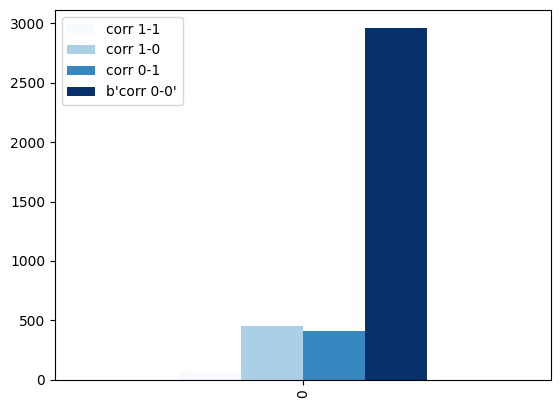

In [14]:
dfvis = pd.DataFrame({ 'corr 1-1': [64],'corr 1-0': [452],'corr 0-1': [412],b'corr 0-0': [2966],})
dfvis.plot(kind = 'bar', colormap= 'Blues')

> **Вывод аудита дубликатов.** Повторные записи не похожи на обычное обновление страницы: интервалы между ними велики (в сохранённом результате нет пар с разницей менее 300 секунд). Почти всегда повторный `user_id` сопровождается несовпадением группы или лендинга. Корреляция конверсии между парами близка к нулю (`≈0,002`). Это допускает гипотезу о технической ошибке идентификаторов, **но не доказывает** её.

В исследовании выбран консервативный способ очистки: оставить первое по времени наблюдение каждого пользователя, затем исключить записи с неправильным сочетанием группы и страницы.

### 2.2 Проверка соответствия группы и страницы

Ожидаемые пары: `control / old_page` и `treatment / new_page`. Сначала посмотрим, как выглядят исходные данные, в том числе среди дублей.

In [15]:
df.groupby(['group', 'landing_page'])['converted'].agg(['mean', 'count'])

mean   count
group     landing_page                  
control   new_page      0.121369    1928
          old_page      0.120386  145274
treatment new_page      0.118807  145311
          old_page      0.127226    1965

In [16]:
dubl = df.duplicated(subset=['user_id'], keep=False)
df[dubl].groupby(['group', 'landing_page'])['converted'].agg(['mean', 'count'])

mean  count
group     landing_page                 
control   new_page      0.121369   1928
          old_page      0.135790   1981
treatment new_page      0.124869   1914
          old_page      0.127226   1965

## 3. Формирование аналитической выборки

**Правило очистки:** для одного пользователя допускается одно набюлдение; каждой группе соответствует её версия страницы. Это устраняет известные нарушения структуры a/b теста

In [18]:
df_sorted = df.sort_values('timestamp') # отсортили по времени
clean_df = df_sorted.drop_duplicates(subset=['user_id'], keep='first') #удалили вторые включения
clean_df = clean_df.reset_index(drop=True)

In [19]:
clean_df.groupby(['group', 'landing_page'])['converted'].agg(['mean', 'count'])

mean   count
group     landing_page                  
control   new_page      0.124103     975
          old_page      0.120393  144319
treatment new_page      0.118698  144316
          old_page      0.138604     974

In [20]:
correct = (
    (clean_df['group'] == 'control') & (clean_df['landing_page'] == 'old_page')
) | (
    (clean_df['group'] == 'treatment') & (clean_df['landing_page'] == 'new_page')
)
clean_df = clean_df[correct] #удалили то что не метчилось

In [21]:
clean_df.groupby(['group', 'landing_page'])['converted'].agg(['mean', 'count'])

,,mean,count
group,landing_page,,
control,old_page,0.120393,144319
treatment,new_page,0.118698,144316


In [22]:
(clean_df['user_id'].value_counts() > 1).sum()

np.int64(0)

> **Результат очистки:** осталось **288 635** наблюдений. После фильтрации нет повторных `user_id`, а каждая запись соответствует ожидаемой комбинации `group` и `landing_page`.



## 4. Проверка сопоставимости групп и поведения метрики во времени

До статистического теста посмотрим, насколько равномерно распределяется трафик между группами и как меняются объём наблюдений и конверсия по часам и датам.

,user_id,timestamp,group,landing_page,converted,huor
0,922696,2025-01-02 13:42:05.378582,treatment,new_page,0,13
1,781507,2025-01-02 13:42:15.234051,control,old_page,0,13
2,737319,2025-01-02 13:42:21.786186,control,old_page,0,13
3,818377,2025-01-02 13:42:26.640581,treatment,new_page,0,13
4,725857,2025-01-02 13:42:27.851110,treatment,new_page,0,13
...,...,...,...,...,...,...
290579,799244,2025-01-24 13:41:15.325359,treatment,new_page,0,13
290580,808330,2025-01-24 13:41:19.152664,control,old_page,0,13
290581,843121,2025-01-24 13:41:44.097174,treatment,new_page,0,13
290582,836373,2025-01-24 13:41:52.604673,control,old_page,0,13


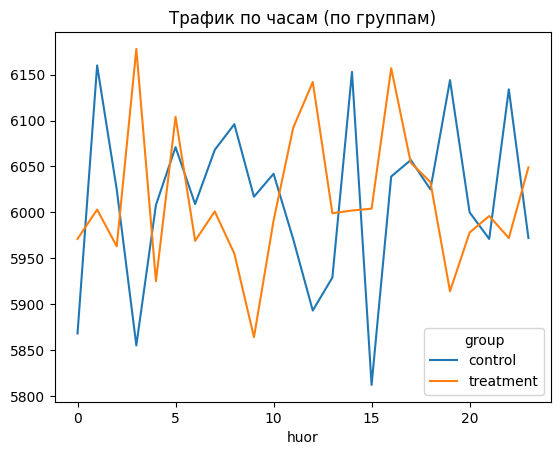

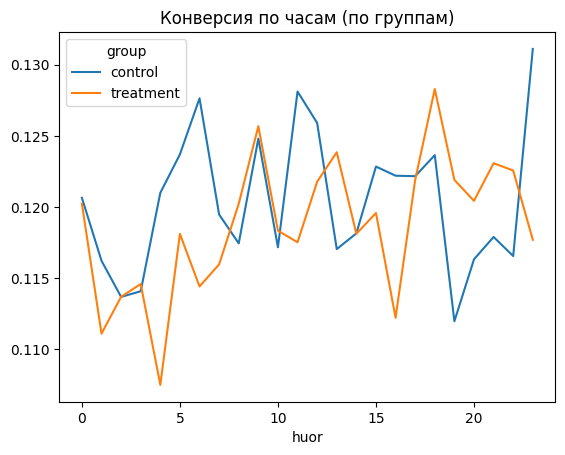

In [23]:
clean_df['huor'] = clean_df['timestamp'].dt.hour #выделили часы
clean_df.groupby(['huor', 'group'])['user_id'].count().unstack().plot( title='Трафик по часам (по группам)') #сделали табличку с индексами часами и двумя столбиками, для каждого будет график
clean_df.groupby(['huor', 'group'])['converted'].mean().unstack().plot( title='Конверсия по часам (по группам)') # принцип тот же но считаем другое
clean_df



In [24]:
clean_df.groupby(['huor', 'group'])['user_id'].count().unstack().describe() #узнаем параметры

group,control,treatment
count,24.000000,24.000000
mean,6013.291667,6013.166667
std,94.018721,76.933436
min,5812.000000,5864.000000
25%,5971.000000,5970.500000
50%,6021.000000,6000.000000
75%,6068.750000,6050.250000
max,6160.000000,6178.000000


In [25]:
clean_df.groupby(['huor', 'group'])['converted'].mean().unstack().describe() #узнаем параметры

group,control,treatment
count,24.000000,24.000000
mean,0.120415,0.118708
std,0.004924,0.004825
min,0.111979,0.107511
25%,0.116930,0.115636
50%,0.120067,0.118966
75%,0.123664,0.121906
max,0.131112,0.128294


<Axes: title={'center': 'Конверсия по датам (по группам)'}, xlabel='date'>

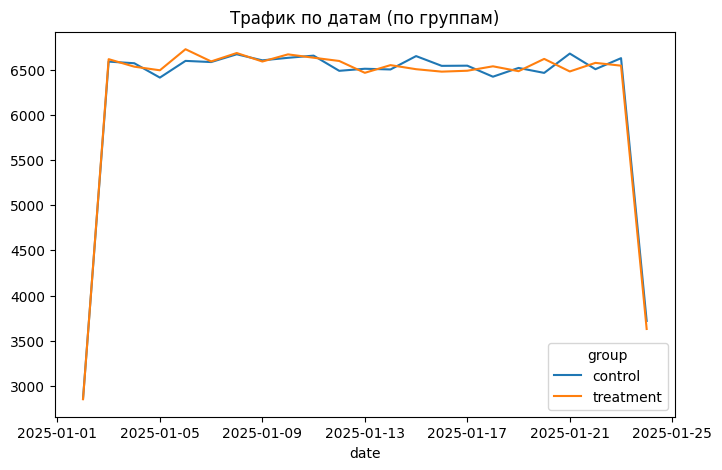

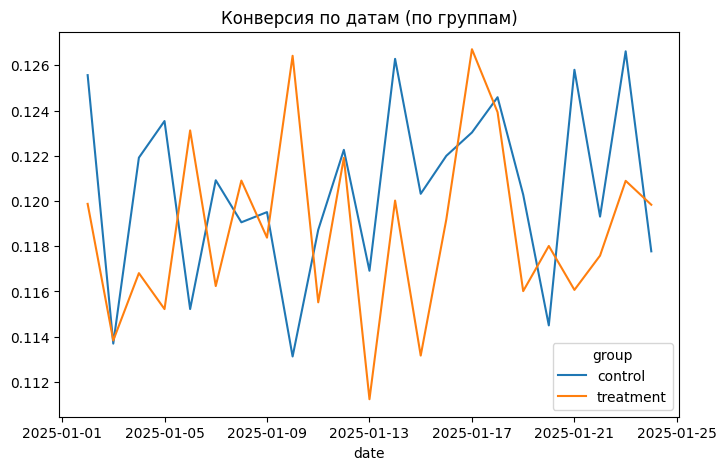

In [26]:
clean_df['date'] = clean_df['timestamp'].dt.date
clean_df.groupby(['date', 'group'])['user_id'].count().unstack().plot(figsize=(8,5), title='Трафик по датам (по группам)') #тут всё похоже но даты а не часы
clean_df.groupby(['date', 'group'])['converted'].mean().unstack().plot(figsize=(8,5), title='Конверсия по датам (по группам)') #аналогично

In [27]:
clean_df.groupby(['date', 'group'])['user_id'].count().unstack().describe()

group,control,treatment
count,23.000000,23.000000
mean,6274.739130,6274.608696
std,953.967324,966.851955
min,2859.000000,2853.000000
25%,6493.500000,6484.500000
50%,6543.000000,6543.000000
75%,6614.000000,6605.000000
max,6677.000000,6725.000000


In [28]:
clean_df.groupby(['date', 'group'])['converted'].mean().unstack().describe()

group,control,treatment
count,23.000000,23.000000
mean,0.120477,0.118734
std,0.004031,0.004008
min,0.113122,0.111231
25%,0.118250,0.116040
50%,0.120319,0.118379
75%,0.123285,0.120898
max,0.126622,0.126715


In [29]:
clean_df.shape

(288635, 7)

In [30]:
clean_df['group'].value_counts(normalize=True)

,proportion
group,
control,0.500005
treatment,0.499995


> **Наблюдение:** по сохранённым графикам и описательной статистике группы близки по размеру, а изменения конверсии во времени не дают очевидного основания разбивать выборку на дополнительные временные когорты.



## 5. Основной результат: проверка гипотезы

**H_0:** конверсии на старой и новой страницах равны.  
**H_1:** конверсии различаются.

Конверсия — бинарный признак, поэтому для сравнения двух долей используется **двусторонний z-тест** (`proportions_ztest`). Порог значимости: **α = 0,05**.

In [31]:
clean_df.groupby('group')['converted'].mean()

,converted
group,
control,0.120393
treatment,0.118698


In [32]:
control = clean_df[clean_df['group'] == 'control']
control_conv = control['converted'].mean()
print(round(control_conv, 4))
treatment = clean_df[clean_df['group'] == 'treatment']
treatment_conv = treatment['converted'].mean()
print(round(treatment_conv, 4))

count = [treatment['converted'].sum(), control['converted'].sum()]
nobs = [len(treatment), len(control)]
z_stat, p_value = proportions_ztest(count, nobs)
print(z_stat)
print(p_value)

0.1204
0.1187
-1.4035742794239752
0.16044565865244198


### Результат статистического теста

| Показатель | Значение |
|---|---:|
| Конверсия control (old_page) | **12,04%** |
| Конверсия treatment (new_page) | **11,87%** |
| Разница treatment − control | **−0,17 п.п.** |
| Z-статистика | **−1,4036** |
| p-value | **0,1604** |

> **Интерпретация:** поскольку `p = 0,1604 > 0,05`, отвергнуть H_0 не удалось. В выборке конверсия новой страницы ниже, однако это различие статистически незначимо. **Оснований рекомендовать внедрение новой версии ради роста конверсии по результатам этого теста нет.**



## 6. Дополнительная оценка неопределённости: бутстрап



Control conversion: 0.12039917935897611
Treatment conversion: 0.11891957956489856
95% Доверительный интервал: -0.003843370014207805 0.0008635786379374505


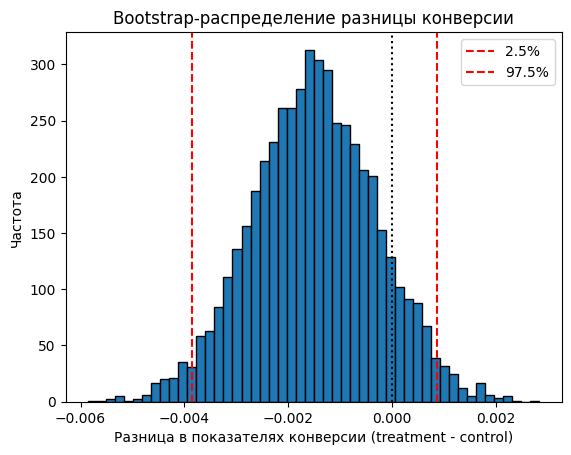

In [33]:


control = df[df["group"] == "control"]["converted"].values  #фильтрует масиив, что бы была группа control и значания конверсии(0или1), .values - делает нампай массив
treatment = df[df["group"] == "treatment"]["converted"].values # аналагично с treatment

print("Control conversion:", np.mean(control)) #вывод среднего значения
print("Treatment conversion:", np.mean(treatment))

# Параметры бутстрапа
n_boot = 5000 #кол-во взятий ресемпла и пересчёта разницы конверсий
n_c = len(control) # число наблюдейний в группе
n_t = len(treatment)

boot_diffs = [] # В него будут записываться значения разницы конверсий (cr_t - cr_c)
                # для каждой бутстрап‑итерации, чтобы потом анализировать их распределение и считать доверительный интервал.


for _ in range(n_boot):
    sample_c = np.random.choice(control, size=n_c, replace=True) # рандомно создаётся выборка из control группы, n_c элементов, с возможностью повторов
    sample_t = np.random.choice(treatment, size=n_t, replace=True)

    cr_c = sample_c.mean() #средняя конверсия для 1 из групп в бутстраппе
    cr_t = sample_t.mean()
    boot_diffs.append(cr_t - cr_c) #вычисляем разницу конверсий текущих выборок и добавляем в boot_diffs.
                                   #5000 таких оценок дадут эмперическое (не поддающееся формулам) распределение

boot_diffs = np.array(boot_diffs) #делаем нампай массив для расчета ДИ и статистики

# 95% Доверительный интервал (ДИ)
ci_low, ci_high = np.percentile(boot_diffs, [2.5, 97.5]) # Считает 2.5‑й и 97.5‑й процентили распределения boot_diffs
print("95% Доверительный интервал:", ci_low, ci_high)

# Гистограмма распределения
plt.hist(boot_diffs, bins=50, edgecolor="black")
plt.axvline(ci_low, color="red", linestyle="--", label="2.5%")
plt.axvline(ci_high, color="red", linestyle="--", label="97.5%")
plt.axvline(0, color="black", linestyle=":")
plt.xlabel("Разница в показателях конверсии (treatment - control)")
plt.ylabel("Частота")
plt.legend()
plt.title("Bootstrap-распределение разницы конверсии")
plt.show()


> **Результат исходного бутстрапа:** 95%-й интервал для `treatment − control` составляет примерно **[−0,386; +0,095] п.п.** и включает ноль. Это согласуется с отсутствием обнаруженного статистически значимого различия


## 7. Итоги и продуктовая интерпретация

| Этап | Что удалось установить |
|---|---|
| **Аудит данных** | Найдены повторные ID и ошибки соответствия групп и страниц; сформирована очищенная выборка |
| **Контроль распределения** | Группы близки по размерам, критических видимых сдвигов во временных срезах не обнаружено |
| **Основной A/B-тест** | Новая страница: **11,87%**, старая: **12,04%**; `p = 0,1604` |
| **Решение** | **Не подтверждено улучшение конверсии** от новой версии по данным этого теста |





